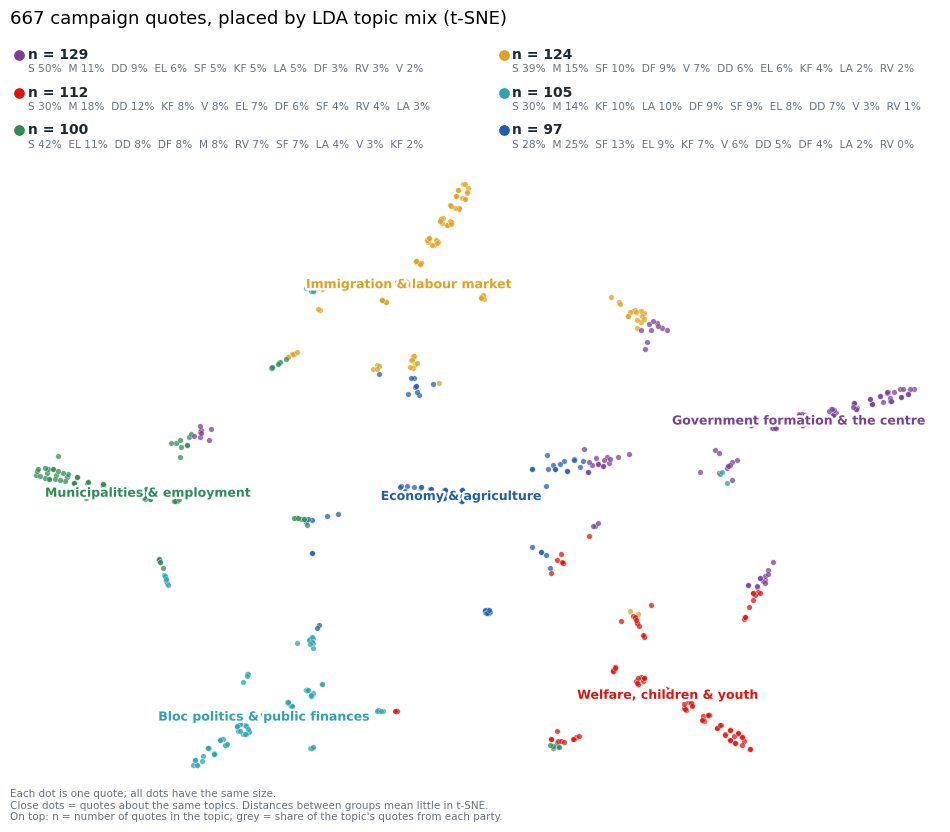

In [6]:
# --- t-SNE of the campaign quotes (LDA), same as the atlas – static version (English) ---
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE

project_root = Path("/Users/salmahirsi/Documents/GitHub/Politics-Network")

# 1. Same data, stopwords and LDA as tfidf.ipynb, so the topics are the atlas topics
df = pd.read_csv(project_root / "data" / "tokenized_citater.csv")
df["tokens"] = df["tokens"].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else [])
df = df.dropna(subset=["parti"])
df = df[df["tokens"].map(len) > 0]
ord_pr_parti = df.groupby("parti")["tokens"].apply(lambda l: sum(map(len, l)))
valid_parties = ord_pr_parti[ord_pr_parti >= 100].index
custom_stopwords = ["sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort", "hel", "få", "gå", "tage", "se", "give",
    "komme", "blive", "gøre", "kunne", "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark", "parti", "partier", "politik", "politisk",
    "valgkamp", "valg", "folketingsvalg", "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann", "jensen", "søren", "pape", "poulsen",
    "pia", "olsen", "dyhr", "inger", "støjberg", "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai",
    "villadsen", "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"]
df_lda = df[df["parti"].isin(valid_parties)].copy()
df_lda = df_lda[df_lda["tokens"].map(len) >= 5].reset_index(drop=True)
count_vec = CountVectorizer(min_df=5, max_df=0.50, stop_words=custom_stopwords)
dtm = count_vec.fit_transform(df_lda["tokens"].apply(" ".join))
lda = LatentDirichletAllocation(n_components=6, random_state=42, max_iter=25)
theta = lda.fit_transform(dtm)
theta = theta / theta.sum(1, keepdims=True)
df_lda["emne"] = theta.argmax(1)

TOPICS = ["Economy & agriculture", "Immigration & labour market", "Municipalities & employment",
          "Government formation & the centre", "Welfare, children & youth", "Bloc politics & public finances"]
EMNE_FARVER = ["#1F5FAD", "#E3A01F", "#2E8B57", "#7B3F98", "#E3120B", "#2BA3B4"]          # atlas colours

# 2. t-SNE exactly as in the atlas: Hellinger distance = Euclidean distance on sqrt(theta)
xy = TSNE(n_components=2, perplexity=min(30, (len(df_lda) - 1) / 3), metric="euclidean", init="pca",
          learning_rate="auto", random_state=42).fit_transform(np.sqrt(theta))
df_lda["x"], df_lda["y"] = xy[:, 0], xy[:, 1]

# 3. Draw: topic legend with all numbers on top, the labelled map below
orden = list(df_lda["emne"].value_counts().index)                       # largest topic first
N = len(df_lda)
andel = pd.crosstab(df_lda["emne"], df_lda["parti"], normalize="index")
fig = plt.figure(figsize=(12, 9.6))
gs = fig.add_gridspec(2, 1, height_ratios=[0.2, 1], hspace=0.0)
top, ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# top: one entry per topic – small dot + name, share of all quotes, and who says it
top.axis("off"); top.set_xlim(-0.01, 2.1); top.set_ylim(-0.05, 1)
for k, i in enumerate(orden):
    x, y = 1.1 * (k % 2), 0.9 - 0.32 * (k // 2)
    n = int((df_lda["emne"] == i).sum())
    top.scatter(x + 0.01, y, s=45, color=EMNE_FARVER[i])
    top.text(x + 0.03, y, f"n = {n}", fontsize=10, fontweight="bold", color="#1f2933", va="center")
    hvem = andel.loc[i].sort_values(ascending=False)
    top.text(x + 0.03, y - 0.12, "  ".join(f"{p} {v:.0%}" for p, v in hvem.items()), fontsize=7.6,
             color="#66717d", va="center")

# map (as before: topic names written on the groups)
for i, f in enumerate(EMNE_FARVER):
    d = df_lda[df_lda["emne"] == i]
    ax.scatter(d["x"], d["y"], s=16, color=f, alpha=0.75, linewidths=0.3, edgecolors="white")
    kerne = d.loc[((d[["x", "y"]] - d[["x", "y"]].median()) ** 2).sum(1).nsmallest(max(5, len(d) // 3)).index]
    ax.text(kerne["x"].median(), kerne["y"].median(), TOPICS[i], ha="center", va="center", fontsize=9,
            fontweight="bold", color=f, path_effects=[pe.withStroke(linewidth=3.5, foreground="white")])
ax.margins(x=0.03, y=0.03)
ax.set_xticks([]); ax.set_yticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.text(0, -0.01, "Each dot is one quote; all dots have the same size.\n"
        "Close dots = quotes about the same topics. Distances between groups mean little in t-SNE.\n"
        "On top: n = number of quotes in the topic; grey = share of the topic's quotes from each party.",
        transform=ax.transAxes, fontsize=7.5, color="#66717d", va="top")

fig.suptitle(f"{N} campaign quotes, placed by LDA topic mix (t-SNE)", fontsize=13, x=0.125, ha="left", y=0.915)
fig.savefig(project_root / "docs" / "assets" / "figures" / "fig_citater_tsne.png", dpi=300, bbox_inches="tight")
plt.show()


In [9]:
fig.savefig("fig_citater_tsne.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_citater_tsne.pdf", bbox_inches="tight")
plt.show()

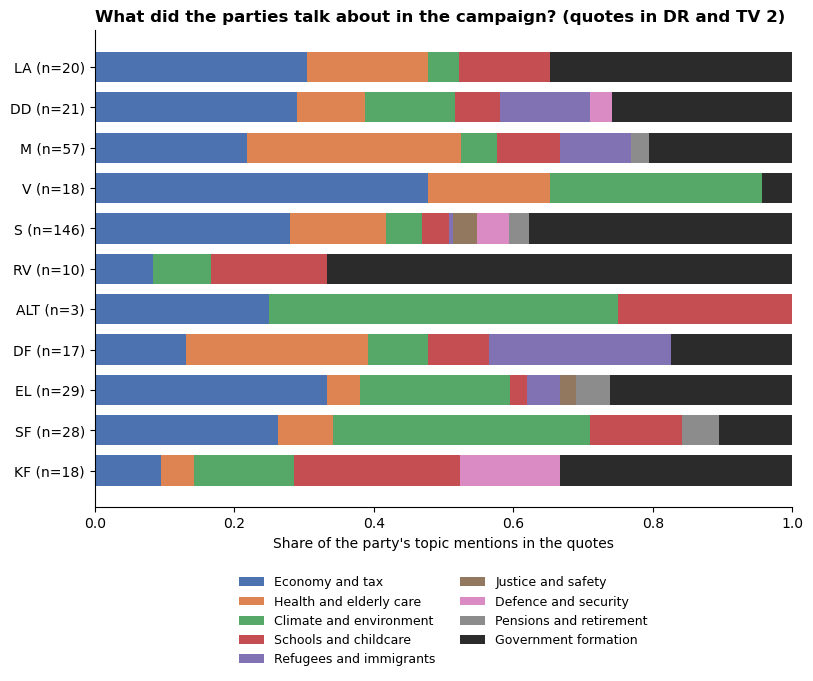

In [8]:
# --- What did the parties talk about in the campaign? (quotes in DR and TV 2) ---
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path("/Users/salmahirsi/Documents/GitHub/Politics-Network")
citater = pd.read_csv(project_root / "data" / "citater_pr_politiker.csv").dropna(subset=["parti"])

# 1. The same 8 topics (keyword stems) as the mærkesager in Figure 1, plus government formation
#    "ord" = word starts with it · "*ord" = may appear inside a word · "=ord" = exactly that word
TOPICS = {
    "Economy and tax": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "arbejdsmarked", "løn"],
    "Health and elderly care": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje"],
    "Climate and environment": ["forurening", "*klima", "grøn", "co2", "vedvarende", "*energiforsyning", "energikrise",
        "energipolitik", "vindmølle", "solcelle", "atomkraft", "fossil", "udledning", "omstilling", "landbrug", "miljø",
        "natur", "biodiversitet", "dyrevelfærd", "drikkevand", "vandmiljø", "grundvand"],
    "Schools and childcare": ["kultur", "*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su",
        "daginstitution", "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer",
        "universitet", "faglært"],
    "Refugees and immigrants": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænsekontrol", "opholdstilladelse"],
    "Justice and safety": ["kriminal", "straf", "=politi", "=politiet", "politibetjent", "vold", "bande", "fængsel",
        "domstol", "retssikkerhed", "retsstat", "retspolitik", "terror"],
    "Defence and security": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pensions and retirement": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist"],
    "Government formation": ["regering", "statsminist", "midte", "*blok", "forhandl", "samarbejd"],
}
COLOURS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#2B2B2B"]

def matches(word, stem):
    if stem.startswith("="):
        return word == stem[1:]
    if stem.startswith("*"):
        return stem[1:] in word
    return word.startswith(stem)

def topics_in(text):
    """Which topics does a quote mention? (one quote can mention several)"""
    words = re.findall(r"[a-zæøåé0-9]+", str(text).lower())
    return [t for t, stems in TOPICS.items() if any(matches(w, s) for w in words for s in stems)]

citater["topics"] = citater["citat"].apply(topics_in)
mentions = citater[["parti", "topics"]].explode("topics").dropna(subset=["topics"]).reset_index(drop=True)

# 2. Share of each party's topic mentions; n = number of quotes that mention at least one topic
PARTIES = ["KF", "SF", "EL", "DF", "ALT", "RV", "S", "V", "M", "DD", "LA"]          # bottom to top
share = pd.crosstab(mentions["parti"], mentions["topics"], normalize="index").reindex(index=PARTIES, columns=list(TOPICS), fill_value=0)
n = citater[citater["topics"].map(len) > 0]["parti"].value_counts()

# 3. Draw
fig, ax = plt.subplots(figsize=(9, 6.2))
left = np.zeros(len(PARTIES))
for topic, colour in zip(TOPICS, COLOURS):
    ax.barh(range(len(PARTIES)), share[topic].values, left=left, color=colour, height=0.75, label=topic)
    left += share[topic].values
ax.set_yticks(range(len(PARTIES)), [f"{p} (n={n.get(p, 0)})" for p in PARTIES])
ax.set_xlim(0, 1)
ax.set_xlabel("Share of the party's topic mentions in the quotes")
ax.set_title("What did the parties talk about in the campaign? (quotes in DR and TV 2)", fontsize=12,
             fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=2, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(project_root / "docs" / "assets" / "figures" / "fig3_citater_emner.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
fig.savefig("fig_citater_emner.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_citater_emner.pdf", bbox_inches="tight")
plt.show()